# Chen 2020 (NPC, 10x) — 04 EMT-TF expression

The unconditional final step (outside the gate chain). Gate 2 was **NO-GO** (embryonic geography absent) and Gate 3 NA, so the branching-only correlation/modules notebooks are not produced; the sequential notebooks are 01-03 + this unconditional expression step -> **04**. This EMT-TF step runs regardless of the gate outcome.

Overlays EMT-transcription-factor expression on the integrated UMAP and reports the **most informative TFs for this dataset**. The panel is chosen by detection, not assumed: the canonical SNAI/ZEB/TWIST factors are screened alongside the FOXC and PRRX families and other mesenchymal TFs; a detection cutoff removes factors that are essentially absent (showing them would be noise). **VIM is excluded** — it is a mesenchymal marker, not a transcription factor.

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1; sc.settings.seed = 0
name='Chen2020_Head-and-Neck-3'; cat='Head-and-Neck'
pth=os.path.join('..', '..', '..', '..')
pth_data=os.path.join(pth,'data')
pth_out=os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig=os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
adata=sc.read_h5ad(os.path.join(pth_out,'processed.h5ad'))
print('loaded processed.h5ad:', adata.shape)

loaded processed.h5ad: (3236, 22080)


### Screen the EMT-TF panel by detection
Candidate panel: the canonical EMT master regulators (SNAI1/2, ZEB1/2, TWIST1/2) plus FOXC1/2, PRRX1/2, and other mesenchymal/EMT-associated TFs (SOX4/9, TCF3/4, RUNX2, TBX3, LEF1, NFATC2, TGFBI). Report each TF's detection fraction and its correlation with pseudotime is characterised in 03; here we keep TFs detected in >=10% of malignant cells for display.

In [1]:
panel=['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2',
       'TCF3','TCF4','SOX4','SOX9','RUNX2','TBX3','LEF1','NFATC2','TGFBI']
present=[g for g in panel if g in adata.var_names]
X=adata[:,present].X; X=np.asarray(X.todense()) if hasattr(X,'todense') else np.asarray(X)
det=(X>0).mean(0); meanexp=X.mean(0)
scr=pd.DataFrame({'gene':present,'detect_frac':det.round(3),'mean_expr':meanexp.round(3)}).sort_values('detect_frac',ascending=False)
print(scr.to_string(index=False))
CUT=0.10
shown=scr[scr.detect_frac>=CUT].gene.tolist()
undetected=scr[scr.detect_frac<CUT].gene.tolist()
print('\nshown (detect>=%.0f%%): %s'%(CUT*100, shown))
print('dropped (near-absent, incl. canonical SNAI1/ZEB1/TWIST1): %s'%undetected)

  gene  detect_frac  mean_expr
  SOX4        0.952      1.316
 PRRX1        0.619      0.358
  TCF4        0.507      0.172
  TCF3        0.406      0.103
  SOX9        0.312      0.079
 SNAI2        0.239      0.068
  LEF1        0.166      0.027
  ZEB2        0.134      0.022
  TBX3        0.134      0.026
 FOXC1        0.129      0.031
NFATC2        0.119      0.030
 RUNX2        0.113      0.020
  ZEB1        0.076      0.011
 TGFBI        0.062      0.024
TWIST2        0.059      0.013
 FOXC2        0.043      0.010
 PRRX2        0.023      0.006
 SNAI1        0.016      0.002
TWIST1        0.009      0.003

shown (detect>=10%): ['SOX4', 'PRRX1', 'TCF4', 'TCF3', 'SOX9', 'SNAI2', 'LEF1', 'ZEB2', 'TBX3', 'FOXC1', 'NFATC2', 'RUNX2']
dropped (near-absent, incl. canonical SNAI1/ZEB1/TWIST1): ['ZEB1', 'TGFBI', 'TWIST2', 'FOXC2', 'PRRX2', 'SNAI1', 'TWIST1']


### expression.pdf — informative EMT-TFs on the integrated UMAP
Each TF displayed with vmax at its 98th percentile so a few high-expressing cells do not wash out the gradient (raw-max scaling hides the pattern on 10x). The dominant factor is **SOX4** (near-ubiquitous, higher at the Gast/embryonic-origin end); **PRRX1** is the main factor rising toward the Crest terminus.

saved expression.pdf with 12 TFs: ['SOX4', 'PRRX1', 'TCF4', 'TCF3', 'SOX9', 'SNAI2', 'LEF1', 'ZEB2', 'TBX3', 'FOXC1', 'NFATC2', 'RUNX2']


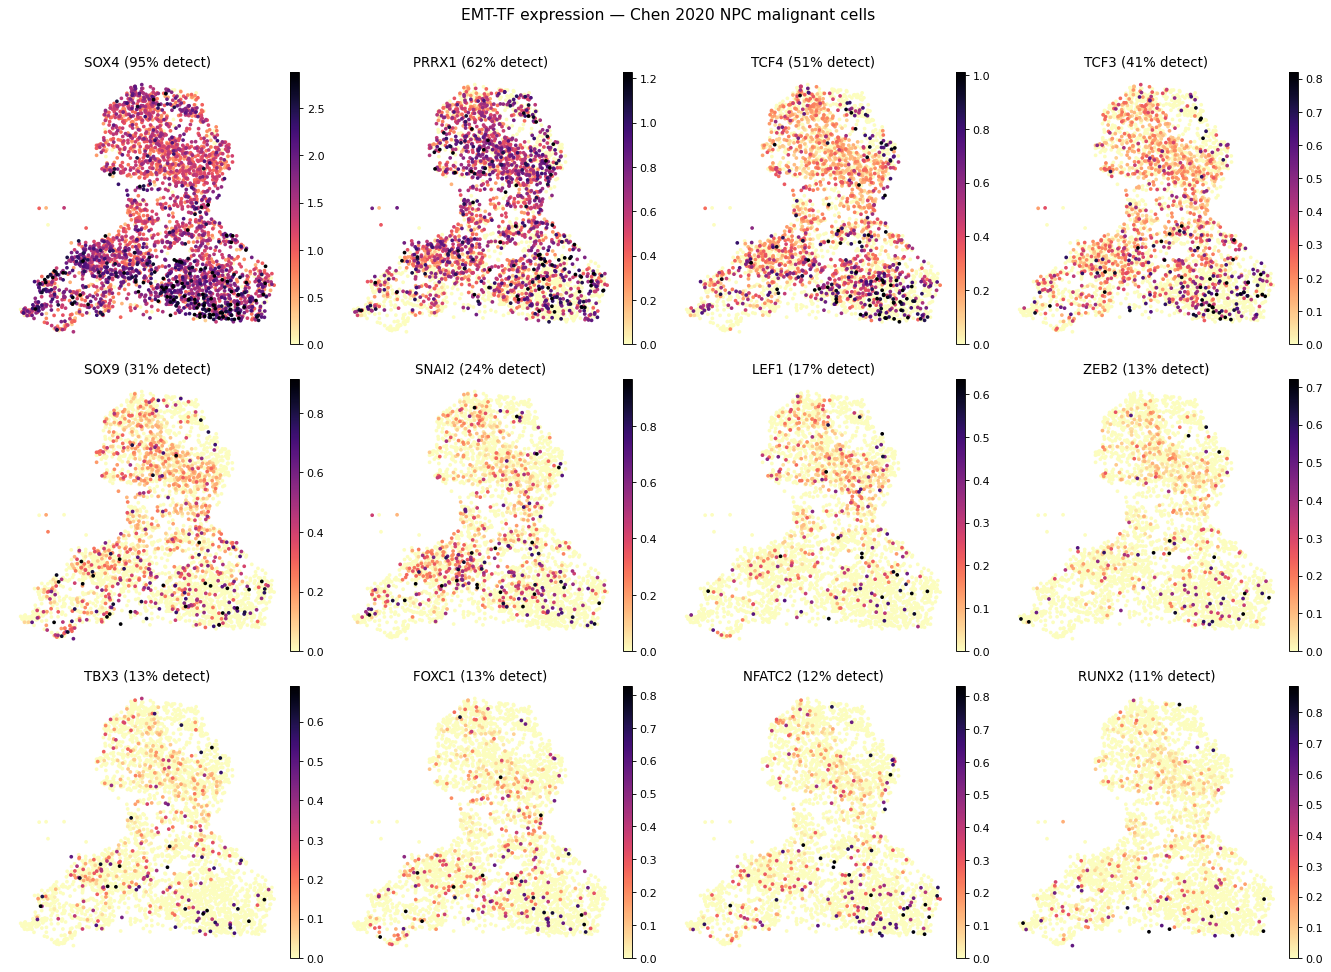

In [1]:
disp=shown  # show ALL genes passing the >=10% detection cutoff
ncol=4; nrow=int(np.ceil(len(disp)/ncol))
fig,axes=plt.subplots(nrow,ncol,figsize=(4.2*ncol,4*nrow))
axes=np.atleast_1d(axes).ravel()
for i,g in enumerate(disp):
    x=np.asarray(adata[:,g].X.todense()).ravel() if hasattr(adata[:,g].X,'todense') else np.asarray(adata[:,g].X).ravel()
    vmax=np.quantile(x[x>0],0.98) if (x>0).any() else 1.0
    sc.pl.umap(adata,color=g,cmap='magma_r',vmax=vmax,size=45,ax=axes[i],show=False,frameon=False,title='%s (%.0f%% detect)'%(g,(x>0).mean()*100))
for j in range(len(disp),len(axes)): axes[j].axis('off')
fig.suptitle('EMT-TF expression — Chen 2020 NPC malignant cells',size=14,y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(pth_fig,'expression.pdf'),bbox_inches='tight')
print('saved expression.pdf with %d TFs: %s'%(len(disp),disp))

### Summary
On Chen 2020 NPC the canonical EMT master regulators are largely undetectable (SNAI1 ~2%, ZEB1 ~8%, TWIST1 ~1% of malignant cells), so a canonical-only panel would be uninformative. The EMT-TF program that *is* expressed is carried by **SOX4** (dominant, embryonic-origin biased) and **PRRX1** (rising toward the Crest-high terminus), with secondary SNAI2 / FOXC1 / TCF3/4 / SOX9. This is the informative panel reported for the dataset.